# CDS 2413 – Programming for Data Analytics
## Project Deliverable 1 (CLO1 & CLO2) — Medical Cost Personal Dataset

**Dataset:** Medical Cost Personal Datasets (`insurance.csv`) — Kaggle
**Records:** 1,338 &nbsp;|&nbsp; **Columns:** `age`, `sex`, `bmi`, `children`, `smoker`, `region`, `charges`

> Place `insurance.csv` in the same folder as this notebook before running.

---
# CLO1 — Planning the Analysis

### Task 1: Purpose of the data analysis
The purpose of this analysis is to understand **what drives individual medical insurance charges** and to
**predict the charges** a person will be billed based on their personal attributes.

Specifically, we want to:
- Summarise how medical charges are distributed across the 1,338 policyholders (average cost, spread, skewness, outliers).
- Find which factors (age, BMI, smoking status, number of children, sex, region) are related to higher charges.
- Test statistical assumptions (correlation, independence, representativeness of samples).
- Build a foundation for a regression model (Deliverable 2) that an insurance company could use to set fair premiums,
  and that individuals could use to understand how lifestyle choices (e.g. smoking, BMI) affect their healthcare costs.

### Task 2: Type of programming used — and why
We use **Python** with a combination of **procedural** and **functional / modular programming** inside a **Jupyter Notebook**:
- **Procedural:** the analysis runs step-by-step (load → sample → describe → visualise → test), which mirrors the data-analysis workflow.
- **Modular / functional:** reusable functions (e.g. `descriptive_stats(sample, field)`, `systematic_sample(...)`) are written once and applied to the
  population, the random sample and the systematic sample, avoiding repeated code.
- **Object-oriented libraries:** we use objects from pandas (`DataFrame`), matplotlib/seaborn (figures) and SciPy.

**Justification:** Python is free, open-source and the industry standard for data analytics. Its libraries cover every stage of this project —
`pandas`/`numpy` (data handling), `matplotlib`/`seaborn` (visualisation), `scipy.stats` (hypothesis testing) and `scikit-learn` (machine learning in D2).
Jupyter lets us combine code, output and explanation in one reproducible report.

### Task 3: Type and purpose of the Machine Learning algorithm
- **Type:** **Supervised learning — Regression.** The target `charges` is a **continuous numeric** value, and the dataset is labelled (we know the charges for every person),
  so supervised regression is the correct family.
- **Algorithms:** **Simple Linear Regression** (one predictor, e.g. `age` → `charges`) and **Multiple Linear Regression** (all relevant predictors → `charges`).
- **Purpose:** to model the relationship between personal attributes and medical charges and to **predict the expected charges for a new person**.
- For the later CLO3 tasks, `charges` can also be converted into classes (e.g. *High* / *Low* cost) for **classification**
  (Logistic Regression, KNN, Naïve Bayes, Decision Tree), and **clustering** (K-Means, Hierarchical — unsupervised) can group customers with similar profiles.

### Task 4: Independent and dependent variables
| Variable | Type | Role | Justification |
|---|---|---|---|
| `charges` | Numeric (continuous) | **Dependent (target, Y)** | It is the outcome we want to explain and predict — the medical cost billed by insurance. It depends on the person's characteristics. |
| `age` | Numeric (discrete) | Independent (X) | Older people generally need more medical care. |
| `bmi` | Numeric (continuous) | Independent (X) | High BMI (obesity) is linked to chronic diseases and higher costs. |
| `children` | Numeric (discrete) | Independent (X) | Number of dependents covered by the plan. |
| `smoker` | Categorical (yes/no) | Independent (X) | Smoking is a major health risk factor — expected to be the strongest driver of charges. |
| `sex` | Categorical (male/female) | Independent (X) | Possible differences in healthcare usage. |
| `region` | Categorical (4 regions) | Independent (X) | Healthcare prices may differ by US region. |

The independent variables are attributes of the person that exist **before** the bill; `charges` is the **result**, so it is the dependent variable.

---
# CLO2 — Descriptive Analysis, Sampling, Visualisation & Hypothesis Testing

## Setup: import libraries and load the dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mirichoi0218/insurance")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Zain Faisal\.cache\kagglehub\datasets\mirichoi0218\insurance\versions\1


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_style('whitegrid')

df = pd.read_csv(os.path.join(path, 'insurance.csv'))
print('Shape:', df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
# Data quality checks
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.5900,0,no,northwest,"1,639.5631"
581,19,male,30.5900,0,no,northwest,"1,639.5631"


In [5]:
# Remove the duplicate record so it does not bias the statistics
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)
df.describe(include='all')

Shape after removing duplicates: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
count,"1,337.0000",1337,"1,337.0000","1,337.0000",1337,1337,"1,337.0000"
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,675,NaN,NaN,1063,364,NaN
mean,39.2221,NaN,30.6635,1.0957,NaN,NaN,"13,279.1215"
std,14.0443,NaN,6.1005,1.2056,NaN,NaN,"12,110.3597"
min,18.0000,NaN,15.9600,0.0000,NaN,NaN,"1,121.8739"
25%,27.0000,NaN,26.2900,0.0000,NaN,NaN,"4,746.3440"
50%,39.0000,NaN,30.4000,1.0000,NaN,NaN,"9,386.1613"
75%,51.0000,NaN,34.7000,2.0000,NaN,NaN,"16,657.7175"


## Task 5: Why perform descriptive analysis on this dataset?
Descriptive analysis is the first step before any modelling because it:
1. **Summarises the dependent variable `charges`** — its centre (mean, median), spread (std, variance, range, IQR) and shape (skewness, kurtosis).
2. **Reveals the distribution shape** — medical charges are expected to be right-skewed (a few very expensive patients), which affects model choice and whether we should transform the data.
3. **Detects outliers and data-quality issues** (missing values, duplicates) that could distort a regression model.
4. **Allows comparison** between the population and samples, so we can check that our samples are representative.
5. **Guides hypothesis testing and feature selection** — e.g. a big difference in mean charges between smokers and non-smokers suggests `smoker` is a key predictor.

## Task 6: Python function for descriptive statistics
The function takes **the sample (DataFrame)** and **the field (column name)** as input, and returns a full set of descriptive statistics.

In [6]:
def descriptive_stats(sample, field):
    """
    Compute descriptive statistics for one numeric field of a sample.

    Parameters
    ----------
    sample : pandas.DataFrame  - the data (population or a sample)
    field  : str               - the column to describe

    Returns
    -------
    pandas.Series with the descriptive statistics
    """
    data = sample[field].dropna()
    n = data.count()
    mean = data.mean()
    std = data.std()                       # sample standard deviation (ddof=1)
    q1, q3 = data.quantile(0.25), data.quantile(0.75)

    result = {
        'Count': n,
        'Mean': mean,
        'Median': data.median(),
        'Mode': data.mode().iloc[0],
        'Standard Deviation': std,
        'Variance': data.var(),
        'Standard Error': std / np.sqrt(n),
        'Minimum': data.min(),
        'Maximum': data.max(),
        'Range': data.max() - data.min(),
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': q3 - q1,
        'Skewness': data.skew(),
        'Kurtosis': data.kurt(),
        'Coefficient of Variation (%)': std / mean * 100,
        'Sum': data.sum(),
    }
    return pd.Series(result, name=field)


# Test the function on the full dataset (population)
pop_stats = descriptive_stats(df, 'charges')
pop_stats.to_frame('Population – charges')

,Population – charges
Count,"1,337.0000"
Mean,"13,279.1215"
Median,"9,386.1613"
Mode,"1,121.8739"
Standard Deviation,"12,110.3597"
Variance,"146,660,811.0060"
Standard Error,331.2008
Minimum,"1,121.8739"
Maximum,"63,770.4280"
Range,"62,648.5541"


## Task 7: Random sampling (n = 150) and descriptive statistics of the dependent variable
Simple random sampling gives every record the same chance of being selected. `random_state=42` makes the result reproducible.

In [7]:
random_sample = df.sample(n=150, random_state=42)
print('Random sample size:', len(random_sample))
display(random_sample.head())

random_stats = descriptive_stats(random_sample, 'charges')
random_stats.to_frame('Random sample – charges')

Random sample size: 150


,age,sex,bmi,children,smoker,region,charges
899,49,male,22.5150,0,no,northeast,"8,688.8589"
1063,29,female,25.6000,4,no,southwest,"5,708.8670"
1255,51,female,36.3850,3,no,northwest,"11,436.7381"
298,31,male,34.3900,3,yes,northwest,"38,746.3551"
237,31,male,38.3900,2,no,southeast,"4,463.2051"


,Random sample – charges
Count,150.0000
Mean,"13,960.7131"
Median,"9,404.5061"
Mode,"1,135.9407"
Standard Deviation,"13,627.7432"
Variance,"185,715,384.8183"
Standard Error,"1,112.7006"
Minimum,"1,135.9407"
Maximum,"63,770.4280"
Range,"62,634.4873"


## Task 8: Systematic sampling with conditions
**Conditions applied:** we focus on **adult policyholders aged 25 and above who have at least one child** (`age >= 25` and `children >= 1`) —
i.e. working-age parents, a key customer group for family insurance plans.

**Method:** from the filtered list, compute the sampling interval `k = N / n`, pick a random starting point between 0 and k−1,
and then select every *k*-th record.

In [8]:
def systematic_sample(data, n, condition=None, random_state=42):
    """
    Systematic sampling: select every k-th record after a random start.

    data      : DataFrame
    n         : desired sample size
    condition : boolean mask (optional) to filter the data first
    """
    population = data[condition] if condition is not None else data
    population = population.reset_index(drop=True)
    N = len(population)
    k = N // n                                        # sampling interval
    rng = np.random.default_rng(random_state)
    start = rng.integers(0, k)                        # random start in [0, k-1]
    indices = np.arange(start, start + k * n, k)      # start, start+k, start+2k, ...
    print(f'Filtered population N = {N}, sample size n = {n}, interval k = {k}, start = {start}')
    return population.iloc[indices]


condition = (df['age'] >= 25) & (df['children'] >= 1)
systematic = systematic_sample(df, n=150, condition=condition)
print('Systematic sample size:', len(systematic))
display(systematic.head())

systematic_stats = descriptive_stats(systematic, 'charges')
systematic_stats.to_frame('Systematic sample – charges')

Filtered population N = 674, sample size n = 150, interval k = 4, start = 0
Systematic sample size: 150


,age,sex,bmi,children,smoker,region,charges
0,28,male,33.0000,3,no,southeast,"4,449.4620"
4,52,female,30.7800,1,no,northeast,"10,797.3362"
8,59,female,27.7200,3,no,southeast,"14,001.1338"
12,62,female,32.9650,3,no,northwest,"15,612.1933"
16,37,female,30.8000,2,no,southeast,"6,313.7590"


,Systematic sample – charges
Count,150.0000
Mean,"14,225.5412"
Median,"9,236.1547"
Mode,"2,902.9065"
Standard Deviation,"11,928.0444"
Variance,"142,278,242.6516"
Standard Error,973.9207
Minimum,"2,902.9065"
Maximum,"58,571.0745"
Range,"55,668.1680"


## Task 9: Detailed descriptive statistics report — dependent variable `charges`
### 9.1 Population vs. random sample vs. systematic sample

In [9]:
report = pd.concat([pop_stats.rename('Population'),
                    random_stats.rename('Random Sample (n=150)'),
                    systematic_stats.rename('Systematic Sample (n=150)')], axis=1)
report

,Population,Random Sample (n=150),Systematic Sample (n=150)
Count,"1,337.0000",150.0000,150.0000
Mean,"13,279.1215","13,960.7131","14,225.5412"
Median,"9,386.1613","9,404.5061","9,236.1547"
Mode,"1,121.8739","1,135.9407","2,902.9065"
Standard Deviation,"12,110.3597","13,627.7432","11,928.0444"
Variance,"146,660,811.0060","185,715,384.8183","142,278,242.6516"
Standard Error,331.2008,"1,112.7006",973.9207
Minimum,"1,121.8739","1,135.9407","2,902.9065"
Maximum,"63,770.4280","63,770.4280","58,571.0745"
Range,"62,648.5541","62,634.4873","55,668.1680"


### 9.2 Charges broken down by the categorical independent variables

In [10]:
for col in ['smoker', 'sex', 'region']:
    print(f'\n===== charges by {col} =====')
    display(df.groupby(col)['charges'].agg(['count', 'mean', 'median', 'std', 'min', 'max']))


===== charges by smoker =====


,count,mean,median,std,min,max
smoker,,,,,,
no,1063,"8,440.6603","7,345.7266","5,992.9738","1,121.8739","36,910.6080"
yes,274,"32,050.2318","34,456.3485","11,541.5472","12,829.4551","63,770.4280"



===== charges by sex =====


,count,mean,median,std,min,max
sex,,,,,,
female,662,"12,569.5788","9,412.9625","11,128.7038","1,607.5101","63,770.4280"
male,675,"13,974.9989","9,377.9047","12,971.9587","1,121.8739","62,592.8731"



===== charges by region =====


,count,mean,median,std,min,max
region,,,,,,
northeast,324,"13,406.3845","10,057.6520","11,255.8031","1,694.7964","58,571.0745"
northwest,324,"12,450.8408","8,976.9772","11,073.1257","1,621.3402","60,021.3990"
southeast,364,"14,735.4114","9,294.1319","13,971.0986","1,121.8739","63,770.4280"
southwest,325,"12,346.9374","8,798.5930","11,557.1791","1,241.5650","52,590.8294"


### 9.3 Outlier detection (IQR method)

In [11]:
q1, q3 = df['charges'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df['charges'] < lower) | (df['charges'] > upper)]

print(f'Lower fence: {lower:,.2f}   Upper fence: {upper:,.2f}')
print(f'Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% of records)')
print('\nSmoker share among outliers:')
print(outliers['smoker'].value_counts(normalize=True).round(3))

# Dataset without outliers (kept separately for comparison)
df_no_outliers = df[(df['charges'] >= lower) & (df['charges'] <= upper)]
print('\nShape without outliers:', df_no_outliers.shape)
descriptive_stats(df_no_outliers, 'charges').to_frame('Charges without outliers')

Lower fence: -13,120.72   Upper fence: 34,524.78
Number of outliers: 139 (10.4% of records)

Smoker share among outliers:
smoker
yes   0.9780
no    0.0220
Name: proportion, dtype: float64

Shape without outliers: (1198, 7)


,Charges without outliers
Count,"1,198.0000"
Mean,"9,934.6718"
Median,"8,411.7550"
Mode,"1,121.8739"
Standard Deviation,"7,240.2170"
Variance,"52,420,742.0165"
Standard Error,209.1815
Minimum,"1,121.8739"
Maximum,"34,472.8410"
Range,"33,350.9671"


In [12]:
# Automatic written summary from the computed numbers
s = pop_stats
smoker_means = df.groupby('smoker')['charges'].mean()
print(f"""DESCRIPTIVE STATISTICS REPORT – charges (n = {int(s['Count'])})
- Central tendency: mean = ${s['Mean']:,.2f}, median = ${s['Median']:,.2f}.
  The mean is much larger than the median, so the distribution is pulled to the right by high-cost patients.
- Spread: std = ${s['Standard Deviation']:,.2f}, range = ${s['Range']:,.2f} (${s['Minimum']:,.2f} to ${s['Maximum']:,.2f}),
  IQR = ${s['IQR']:,.2f}, coefficient of variation = {s['Coefficient of Variation (%)']:.1f}% -> very high variability.
- Shape: skewness = {s['Skewness']:.3f} (> 1 = strongly right-skewed), kurtosis = {s['Kurtosis']:.3f}.
- Outliers: {len(outliers)} records above ${upper:,.2f}; {outliers['smoker'].eq('yes').mean()*100:.0f}% of them are smokers.
- Smokers pay on average ${smoker_means['yes']:,.2f} vs ${smoker_means['no']:,.2f} for non-smokers
  (about {smoker_means['yes']/smoker_means['no']:.1f}x more).
- Random sample mean = ${random_stats['Mean']:,.2f}; systematic sample mean = ${systematic_stats['Mean']:,.2f}.
""")

DESCRIPTIVE STATISTICS REPORT – charges (n = 1337)
- Central tendency: mean = $13,279.12, median = $9,386.16.
  The mean is much larger than the median, so the distribution is pulled to the right by high-cost patients.
- Spread: std = $12,110.36, range = $62,648.55 ($1,121.87 to $63,770.43),
  IQR = $11,911.37, coefficient of variation = 91.2% -> very high variability.
- Shape: skewness = 1.515 (> 1 = strongly right-skewed), kurtosis = 1.604.
- Outliers: 139 records above $34,524.78; 98% of them are smokers.
- Smokers pay on average $32,050.23 vs $8,440.66 for non-smokers
  (about 3.8x more).
- Random sample mean = $13,960.71; systematic sample mean = $14,225.54.



**Interpretation:**
- `charges` is **not normally distributed** — it is strongly **right-skewed**: most people have low-to-moderate charges, while a smaller group has very high charges.
- The high-charge outliers are **genuine observations** (mostly smokers), not data errors, so they are **kept for modelling** but noted; a log transformation of `charges` may be considered in D2.
- **Smoking status** shows by far the largest difference in charges, making it the most important predictor to investigate.
- The **random sample** statistics are close to the population, showing it is representative. The **systematic sample** is drawn from a filtered sub-group (parents aged 25+),
  so its values describe that sub-group; its mean is slightly higher than the population mean (older people tend to have higher charges).

## Task 10: Visualising the dependent variable
### 10a. Scatter plot

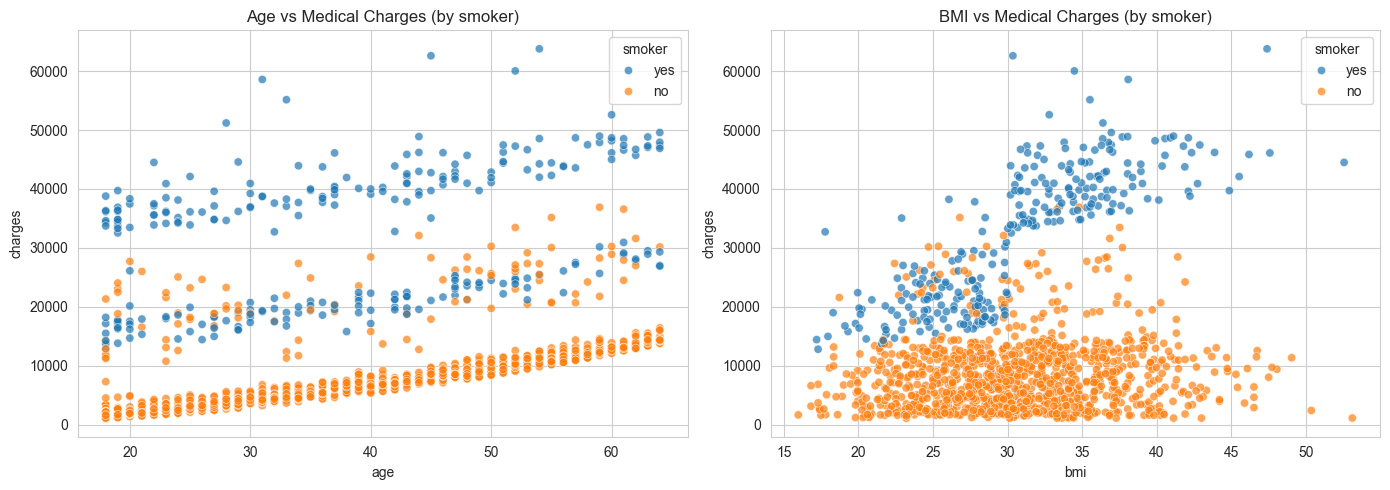

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[0])
axes[0].set_title('Age vs Medical Charges (by smoker)')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[1])
axes[1].set_title('BMI vs Medical Charges (by smoker)')

plt.tight_layout()
plt.show()

**Observation:** charges rise with **age** in three visible bands — non-smokers (bottom), a mixed middle band, and smokers (top).
For **BMI**, smokers with BMI above ~30 form a distinct high-cost group, while for non-smokers BMI has little effect.

### 10b. Box plot

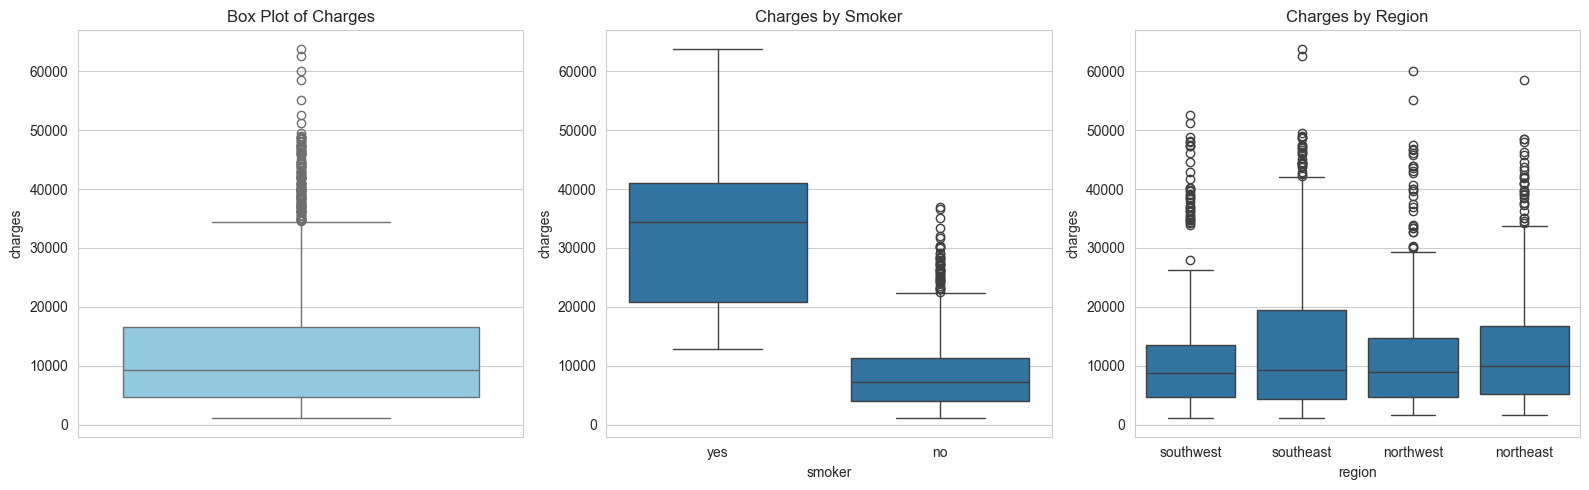

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=df['charges'], ax=axes[0], color='skyblue')
axes[0].set_title('Box Plot of Charges')

sns.boxplot(data=df, x='smoker', y='charges', ax=axes[1])
axes[1].set_title('Charges by Smoker')

sns.boxplot(data=df, x='region', y='charges', ax=axes[2])
axes[2].set_title('Charges by Region')

plt.tight_layout()
plt.show()

**Observation:** the overall box plot shows many outliers above the upper whisker. Smokers have a much higher median and spread than non-smokers;
differences between regions are small.

### 10c. Histogram

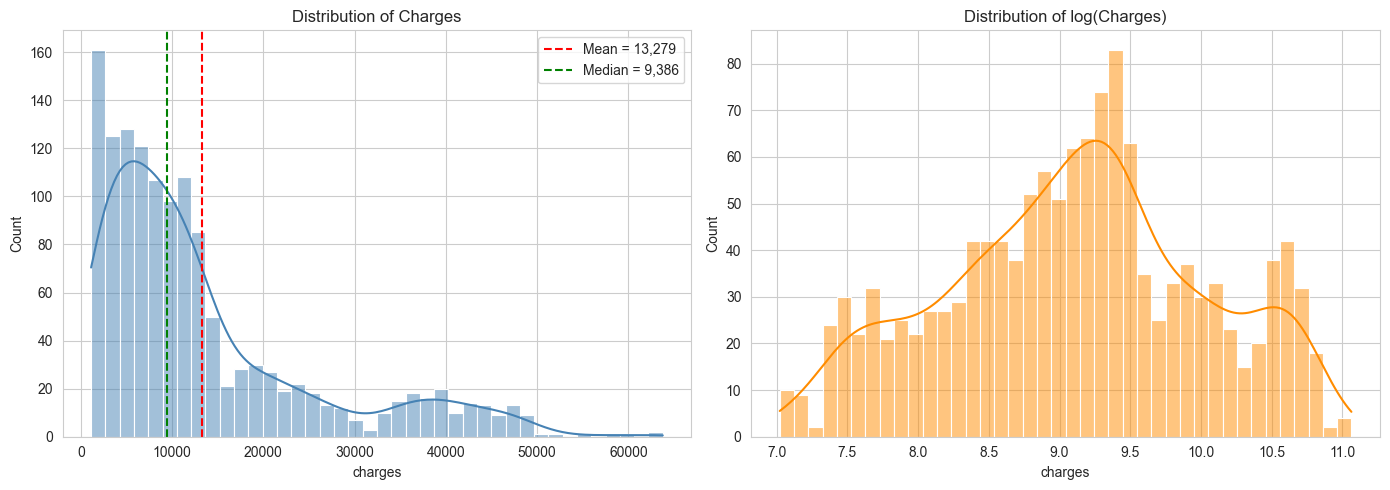

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['charges'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df['charges'].mean(), color='red', linestyle='--', label=f"Mean = {df['charges'].mean():,.0f}")
axes[0].axvline(df['charges'].median(), color='green', linestyle='--', label=f"Median = {df['charges'].median():,.0f}")
axes[0].set_title('Distribution of Charges')
axes[0].legend()

sns.histplot(np.log(df['charges']), bins=40, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribution of log(Charges)')

plt.tight_layout()
plt.show()

**Observation:** the histogram confirms a **right-skewed** distribution (mean > median). The log-transformed version is much closer to a bell shape.

### 10d. Heat map (correlation matrix)

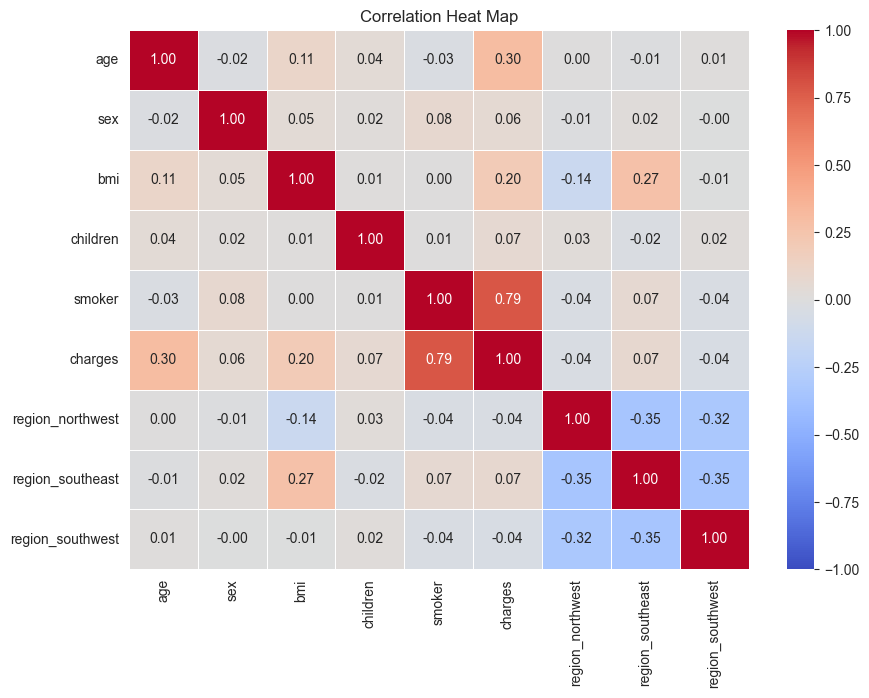

Correlation of each variable with charges:
smoker              0.7870
age                 0.2980
bmi                 0.1980
region_southeast    0.0740
children            0.0670
sex                 0.0580
region_northwest   -0.0390
region_southwest   -0.0440
Name: charges, dtype: float64


In [16]:
# Encode the categorical variables numerically so they can be included in the correlation matrix
df_encoded = df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})
df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=True, dtype=int)

corr = df_encoded.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heat Map')
plt.show()

print('Correlation of each variable with charges:')
print(corr['charges'].drop('charges').sort_values(ascending=False).round(3))

**Observation:** `smoker` has the strongest correlation with `charges`, followed by `age` and `bmi`. `sex`, `children` and region have weak correlations.

## Task 11: Hypothesis tests for correlation
Chosen independent variables: **`age`** (numerical) for Pearson & Spearman, and **`smoker`** (categorical) for Chi-square. Significance level **α = 0.05**.

### 11a. Pearson correlation (age vs charges) — linear relationship
- **H₀:** There is no linear correlation between age and charges (ρ = 0).
- **H₁:** There is a significant linear correlation between age and charges (ρ ≠ 0).

In [17]:
alpha = 0.05

r, p_pearson = stats.pearsonr(df['age'], df['charges'])
print(f'Pearson r = {r:.4f}, p-value = {p_pearson:.4e}')
if p_pearson < alpha:
    print('Reject H0 -> there is a statistically significant linear correlation between age and charges.')
else:
    print('Fail to reject H0 -> no significant linear correlation between age and charges.')

Pearson r = 0.2983, p-value = 6.9757e-29
Reject H0 -> there is a statistically significant linear correlation between age and charges.


### 11b. Spearman rank correlation (age vs charges) — monotonic relationship
Spearman does not assume normality, which suits the skewed `charges` variable.
- **H₀:** There is no monotonic correlation between age and charges.
- **H₁:** There is a significant monotonic correlation between age and charges.

In [18]:
rho, p_spearman = stats.spearmanr(df['age'], df['charges'])
print(f'Spearman rho = {rho:.4f}, p-value = {p_spearman:.4e}')
if p_spearman < alpha:
    print('Reject H0 -> there is a statistically significant monotonic correlation between age and charges.')
else:
    print('Fail to reject H0 -> no significant monotonic correlation between age and charges.')

Spearman rho = 0.5335, p-value = 3.1878e-99
Reject H0 -> there is a statistically significant monotonic correlation between age and charges.


### 11c. Chi-square test of independence (smoker vs charges category)
Chi-square needs two categorical variables, so `charges` is grouped into **Low** (≤ median) and **High** (> median).
- **H₀:** Smoking status and charge level are independent.
- **H₁:** Smoking status and charge level are associated (dependent).

In [19]:
df['charges_level'] = np.where(df['charges'] > df['charges'].median(), 'High', 'Low')

contingency = pd.crosstab(df['smoker'], df['charges_level'])
print('Contingency table (observed):')
display(contingency)

chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print('Expected frequencies:')
display(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(2))
print(f'Chi-square = {chi2:.4f}, degrees of freedom = {dof}, p-value = {p_chi:.4e}')
if p_chi < alpha:
    print('Reject H0 -> smoking status and charge level are significantly associated.')
else:
    print('Fail to reject H0 -> no significant association between smoking status and charge level.')

Contingency table (observed):


charges_level,High,Low
smoker,,
no,394,669
yes,274,0


Expected frequencies:


charges_level,High,Low
smoker,,
no,531.1000,531.9000
yes,136.9000,137.1000


Chi-square = 342.6296, degrees of freedom = 1, p-value = 1.7068e-76
Reject H0 -> smoking status and charge level are significantly associated.


In [20]:
# Summary of the correlation tests
pd.DataFrame({
    'Test': ['Pearson', 'Spearman', 'Chi-square'],
    'Variables': ['age vs charges', 'age vs charges', 'smoker vs charges_level'],
    'Statistic': [r, rho, chi2],
    'p-value': [p_pearson, p_spearman, p_chi],
    'Decision (α=0.05)': ['Reject H0' if p < alpha else 'Fail to reject H0'
                          for p in [p_pearson, p_spearman, p_chi]]
})

,Test,Variables,Statistic,p-value,Decision (α=0.05)
0,Pearson,age vs charges,0.2983,0.0000,Reject H0
1,Spearman,age vs charges,0.5335,0.0000,Reject H0
2,Chi-square,smoker vs charges_level,342.6296,0.0000,Reject H0


## Task 12: One-sample t-test — is the sample representative of the population?
We compare the **mean charges of the random sample (n = 150)** with the **population mean**.
- **H₀:** The sample mean equals the population mean (μ_sample = μ_population) → the sample is representative.
- **H₁:** The sample mean is different from the population mean → the sample is not representative.

In [21]:
population_mean = df['charges'].mean()

t_stat, p_t = stats.ttest_1samp(random_sample['charges'], popmean=population_mean)
print(f'Population mean charges : {population_mean:,.2f}')
print(f'Random sample mean      : {random_sample["charges"].mean():,.2f}')
print(f't-statistic = {t_stat:.4f}, p-value = {p_t:.4f}')
if p_t < alpha:
    print('Reject H0 -> the random sample mean differs significantly; the sample is NOT representative.')
else:
    print('Fail to reject H0 -> no significant difference; the random sample IS representative of the population.')

Population mean charges : 13,279.12
Random sample mean      : 13,960.71
t-statistic = 0.6126, p-value = 0.5411
Fail to reject H0 -> no significant difference; the random sample IS representative of the population.


In [22]:
# Same test on the systematic sample (drawn from a filtered sub-group) for comparison
t_sys, p_sys = stats.ttest_1samp(systematic['charges'], popmean=population_mean)
print(f'Systematic sample mean : {systematic["charges"].mean():,.2f}')
print(f't-statistic = {t_sys:.4f}, p-value = {p_sys:.4f}')
print('Reject H0 -> not representative of the whole population' if p_sys < alpha
      else 'Fail to reject H0 -> representative of the whole population')

Systematic sample mean : 14,225.54
t-statistic = 0.9718, p-value = 0.3327
Fail to reject H0 -> representative of the whole population


In [23]:
# 95% confidence interval for the random-sample mean
ci = stats.t.interval(0.95, df=len(random_sample) - 1,
                      loc=random_sample['charges'].mean(),
                      scale=stats.sem(random_sample['charges']))
print(f'95% CI for mean charges (random sample): {ci[0]:,.2f} to {ci[1]:,.2f}')
print('Population mean inside the CI:', ci[0] <= population_mean <= ci[1])

95% CI for mean charges (random sample): 11,762.00 to 16,159.42
Population mean inside the CI: True


**Note on assumptions:** the t-test assumes the sample mean is approximately normally distributed. Although `charges` is skewed,
with n = 150 the **Central Limit Theorem** makes the sampling distribution of the mean approximately normal, so the t-test is valid.

---
## Conclusion (Deliverable 1)
- `charges` (dependent variable) is right-skewed with high variability and genuine high-value outliers, mostly smokers.
- `smoker`, `age` and `bmi` are the variables most related to charges; correlation and chi-square tests confirm significant relationships.
- The random sample of 150 records is representative of the population (one-sample t-test), so sample-based conclusions can be generalised.
- These findings prepare the data for the regression, classification and clustering models in Deliverable 2.

---
---
# Deliverable 2 — CLO3: Machine Learning Models
This part continues from Deliverable 1 and uses the **same dataset** (`df`, 1,337 records after removing the duplicate).

**Contents**
1. Preprocessing — data collection, cleaning, categorical encoding, splitting, feature scaling
2. Regression — Multiple Linear, Polynomial, Ridge, Lasso, Elastic Net (+ Random Forest & Gradient Boosting as extra models)
3. Regression equation and substitution of 5 random records
4. Classification — Logistic Regression, KNN, Naïve Bayes, SVM, Decision Tree, Random Forest (+ Gradient Boosting)
5. Number of elements in each category using the best classifier
6. Cluster analysis — K-Means and Hierarchical, with a strategy for each cluster

In [24]:
# Libraries for Deliverable 2
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, silhouette_score)
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

## 1. Preprocessing
### 1.1 Data Collection
The data is read from the CSV file with **pandas** (`pd.read_csv`) — this was already done in D1 (`df`). For Excel files `pd.read_excel` would be used.
The **dependent variable (y)** is `charges`; the **independent variables (X)** are all the other columns.

In [25]:
# Start from a fresh copy of the D1 data (drop the helper column created in D1 task 11)
data = df.drop(columns=['charges_level'], errors='ignore').copy()

dependent = 'charges'
independent = [c for c in data.columns if c != dependent]
print('Dependent variable  (y):', dependent)
print('Independent variables (X):', independent)
print('Shape:', data.shape)
data.head()

Dependent variable  (y): charges
Independent variables (X): ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Shape: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


### 1.2 Data Cleaning
Strategies used:
1. **Missing values** — checked with `isnull()`. If any existed, numeric columns would be filled with the **mean** and categorical columns with the **mode**.
2. **Duplicates** — 1 duplicate row was removed in D1.
3. **Outliers in the independent variables** — detected with the **IQR method** (values outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`) and removed.
   Outliers in `charges` (the target) are **kept**, because they are genuine high-cost patients (mostly smokers) that the model must learn to predict.

In [26]:
# 1) Missing values (fill strategy shown, even though the dataset has none)
print('Missing values before:', data.isnull().sum().sum())
for col in data.columns:
    if data[col].dtype.kind in 'if':
        data[col] = data[col].fillna(data[col].mean())
    else:
        data[col] = data[col].fillna(data[col].mode()[0])
print('Missing values after :', data.isnull().sum().sum())

# 2) Duplicates
print('Duplicate rows:', data.duplicated().sum())

Missing values before: 0
Missing values after : 0
Duplicate rows: 0


In [27]:
# 3) Outlier detection on the numeric independent variables (IQR method)
outlier_list = []
for col in ['age', 'bmi', 'children']:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = data[(data[col] < lower) | (data[col] > upper)]
    print(f'{col:9s}: bounds [{lower:.2f}, {upper:.2f}] -> {len(out)} outliers')
    outlier_list.append(out)

# Combine the outliers of all variables and remove duplicates
all_outliers = pd.concat(outlier_list).drop_duplicates()
print('\nTotal outlier rows:', len(all_outliers))
display(all_outliers)

# Remove the outlier rows
data = data.drop(index=all_outliers.index).reset_index(drop=True)
print('Shape after removing outliers:', data.shape)

age      : bounds [-9.00, 87.00] -> 0 outliers
bmi      : bounds [13.67, 47.32] -> 9 outliers
children : bounds [-3.00, 5.00] -> 0 outliers

Total outlier rows: 9


,age,sex,bmi,children,smoker,region,charges
116,58,male,49.0600,0,no,southeast,"11,381.3254"
286,46,female,48.0700,2,no,northeast,"9,432.9253"
401,47,male,47.5200,1,no,southeast,"8,083.9198"
543,54,female,47.4100,0,yes,southeast,"63,770.4280"
846,23,male,50.3800,1,no,southeast,"2,438.0552"
859,37,female,47.6000,2,yes,southwest,"46,113.5110"
1046,22,male,52.5800,1,yes,southeast,"44,501.3982"
1087,52,male,47.7400,1,no,southeast,"9,748.9106"
1316,18,male,53.1300,0,no,southeast,"1,163.4627"


Shape after removing outliers: (1328, 7)


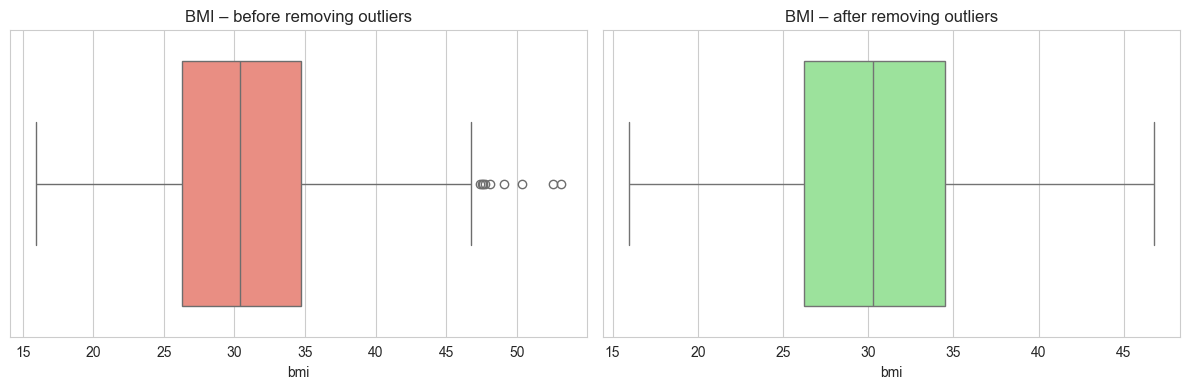

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['bmi'], ax=axes[0], color='salmon').set_title('BMI – before removing outliers')
sns.boxplot(x=data['bmi'], ax=axes[1], color='lightgreen').set_title('BMI – after removing outliers')
plt.tight_layout()
plt.show()

### 1.3 Treating the Categorical Variables
| Variable | Role | Type | Encoding | Reason |
|---|---|---|---|---|
| `sex` | Independent | Nominal – **binary** (female/male) | Label encoding 0/1 | Only two values → one 0/1 column is enough |
| `smoker` | Independent | Nominal – **binary** (no/yes) | Label encoding 0/1 | Only two values → one 0/1 column is enough |
| `region` | Independent | **Nominal** (4 regions, no order) | **One-hot encoding** (`drop_first=True`) | No natural order, so label numbers 0–3 would create a false ranking; dropping one dummy avoids the dummy-variable trap (multicollinearity) |
| `charges` | Dependent | Numeric (continuous) | None for regression | For classification it is converted into a **binary/ordinal** category (Low/High) in Section 4 |

In [29]:
data_enc = data.copy()
data_enc['sex'] = data_enc['sex'].map({'female': 0, 'male': 1})
data_enc['smoker'] = data_enc['smoker'].map({'no': 0, 'yes': 1})
data_enc = pd.get_dummies(data_enc, columns=['region'], drop_first=True, dtype=int)
data_enc.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.9000,0,1,"16,884.9240",0,0,1
1,18,1,33.7700,1,0,"1,725.5523",0,1,0
2,28,1,33.0000,3,0,"4,449.4620",0,1,0
3,33,1,22.7050,0,0,"21,984.4706",1,0,0
4,32,1,28.8800,0,0,"3,866.8552",1,0,0


### 1.4 Splitting the Dataset
The data is split into **80% training** and **20% testing** sets. The model learns only from the training set and is evaluated on unseen test data,
which shows how well it generalises and helps detect overfitting. 80/20 is a common split that leaves enough data for training (~1,060 rows)
while keeping a reliable test set (~266 rows). `random_state=42` makes the split reproducible.

In [30]:
X = data_enc.drop(columns='charges')
y = data_enc['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('Features:', list(X.columns))

X_train: (1062, 8)  X_test: (266, 8)
Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']


### 1.5 Feature Scaling
Yes — **StandardScaler** (z-score: `(x − mean) / std`) is applied where the algorithm needs it:
- **Ridge, Lasso, Elastic Net**: the penalty acts on coefficient size, so features must be on the same scale (age 18–64 vs bmi 16–47 vs 0/1 dummies).
- **KNN, SVM, Logistic Regression, K-Means, Hierarchical**: distance- or gradient-based, so large-range features would dominate.
- **Not needed** for plain Linear/Polynomial Regression (OLS is scale-invariant), Naïve Bayes and tree-based models.

The scaler is placed inside a **Pipeline**, so it is fitted on the training data only (no data leakage).

In [31]:
scaler_demo = StandardScaler().fit(X_train)
pd.DataFrame(scaler_demo.transform(X_train), columns=X.columns).describe().loc[['mean', 'std']].round(3)

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
mean,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 2. Regression Models
Models: **Multiple Linear Regression, Polynomial Regression (degree 2), Ridge, Lasso, Elastic Net**.
The regularisation strength (`alpha`) of Ridge, Lasso and Elastic Net is **optimised with 5-fold GridSearchCV**.
Random Forest and Gradient Boosting are added as extra models for comparison.

In [32]:
cv5 = 5
reg_models = {
    'Multiple Linear Regression': LinearRegression(),
    'Polynomial Regression (deg 2)': make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    'Ridge Regression': GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                                     {'ridge__alpha': [0.01, 0.1, 1, 10, 50, 100]}, cv=cv5, scoring='r2'),
    'Lasso Regression': GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=50000)),
                                     {'lasso__alpha': [0.1, 1, 10, 50, 100, 200]}, cv=cv5, scoring='r2'),
    'Elastic Net Regression': GridSearchCV(make_pipeline(StandardScaler(), ElasticNet(max_iter=50000)),
                                           {'elasticnet__alpha': [0.001, 0.01, 0.1, 1],
                                            'elasticnet__l1_ratio': [0.2, 0.5, 0.8, 1.0]}, cv=cv5, scoring='r2'),
    # Extra models (beyond the lecture slides)
    'Random Forest Regressor': RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
}

reg_results, reg_predictions = [], {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    reg_predictions[name] = y_pred
    mse = mean_squared_error(y_test, y_pred)
    reg_results.append({'Model': name,
                        'MSE': mse,
                        'RMSE': np.sqrt(mse),
                        'MAE': mean_absolute_error(y_test, y_pred),
                        'R2': r2_score(y_test, y_pred)})
    if isinstance(model, GridSearchCV):
        print(f'{name}: best parameters = {model.best_params_}')

reg_df = pd.DataFrame(reg_results).sort_values('R2', ascending=False).reset_index(drop=True)
reg_df

Ridge Regression: best parameters = {'ridge__alpha': 10}
Lasso Regression: best parameters = {'lasso__alpha': 50}
Elastic Net Regression: best parameters = {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.2}


,Model,MSE,RMSE,MAE,R2
0,Random Forest Regressor,"21,267,917.1950","4,611.7152","2,630.2659",0.8470
1,Gradient Boosting Regressor,"22,186,784.2190","4,710.2849","2,638.4779",0.8404
2,Polynomial Regression (deg 2),"23,065,553.6811","4,802.6611","2,857.6857",0.8341
3,Lasso Regression,"35,188,517.4371","5,931.9910","4,090.8749",0.7468
4,Ridge Regression,"35,387,273.8316","5,948.7204","4,128.5752",0.7454
5,Elastic Net Regression,"35,397,504.1878","5,949.5802","4,128.0101",0.7453
6,Multiple Linear Regression,"35,465,549.2404","5,955.2959","4,125.9427",0.7448


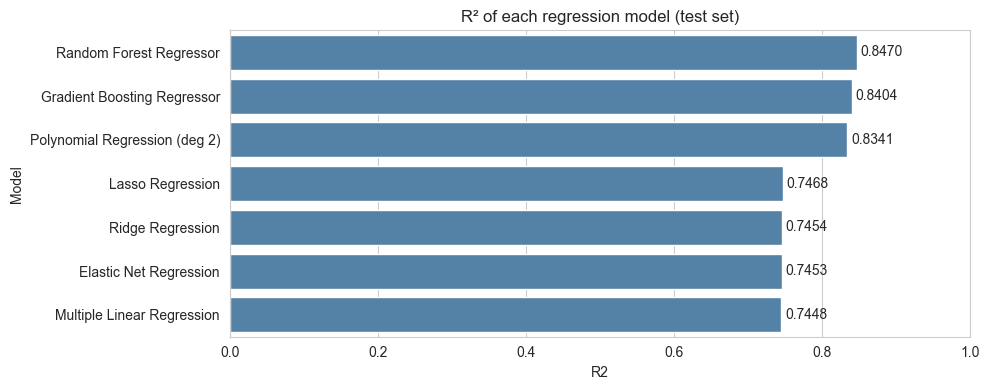

In [33]:
plt.figure(figsize=(10, 4))
sns.barplot(data=reg_df, x='R2', y='Model', color='steelblue')
for i, v in enumerate(reg_df['R2']):
    plt.text(v + 0.005, i, f'{v:.4f}', va='center')
plt.xlim(0, 1)
plt.title('R² of each regression model (test set)')
plt.tight_layout()
plt.show()

### 2.1 Selecting the Best-Fit Model
The model with the **highest R²** is selected. Because the regression equation must be written from the **intercept and coefficients**,
the best model is chosen among the five equation-based models (Linear, Polynomial, Ridge, Lasso, Elastic Net).
The tree-based extra models are shown for comparison only (they do not produce an equation).

In [34]:
equation_models = ['Multiple Linear Regression', 'Polynomial Regression (deg 2)',
                   'Ridge Regression', 'Lasso Regression', 'Elastic Net Regression']
best_overall = reg_df.iloc[0]
best_eq = reg_df[reg_df['Model'].isin(equation_models)].iloc[0]

print(f"Best model overall           : {best_overall['Model']} (R² = {best_overall['R2']:.4f})")
print(f"Best equation-based model    : {best_eq['Model']} (R² = {best_eq['R2']:.4f})")
best_reg_name = best_eq['Model']
best_reg = reg_models[best_reg_name]

Best model overall           : Random Forest Regressor (R² = 0.8470)
Best equation-based model    : Polynomial Regression (deg 2) (R² = 0.8341)


### 2.2 Regression Equations

In [35]:
def print_equation(name, model, feature_names):
    """Print the regression equation in the ORIGINAL units of the features."""
    if isinstance(model, GridSearchCV):
        model = model.best_estimator_
    if hasattr(model, 'steps'):
        steps = dict(model.steps)
        last = model.steps[-1][1]
        if 'polynomialfeatures' in steps:
            names = [n.replace(' ', '*') for n in steps['polynomialfeatures'].get_feature_names_out(feature_names)]
            coefs, intercept = last.coef_, last.intercept_
        else:                                   # StandardScaler + linear model -> convert to original units
            sc = steps['standardscaler']
            coefs = last.coef_ / sc.scale_
            intercept = last.intercept_ - np.sum(last.coef_ * sc.mean_ / sc.scale_)
            names = feature_names
    else:
        coefs, intercept, names = model.coef_, model.intercept_, feature_names

    terms = ' '.join(f"{'+' if c >= 0 else '-'} {abs(c):,.4f}*{n}" for c, n in zip(coefs, names) if abs(c) > 1e-8)
    print(f'{name}:\ncharges = {intercept:,.4f} {terms}\n')
    return intercept, pd.Series(coefs, index=names)

eq_params = {}
for name in equation_models:
    eq_params[name] = print_equation(name, reg_models[name], list(X.columns))

Multiple Linear Regression:
charges = -12,180.8696 + 259.0302*age - 38.6881*sex + 349.2414*bmi + 529.4646*children + 23,743.3058*smoker - 574.6780*region_northwest - 1,302.6095*region_southeast - 1,549.5051*region_southwest

Polynomial Regression (deg 2):
charges = -1,083.4885 - 106.5778*age - 795.6535*sex + 333.6139*bmi + 2,023.1641*children - 10,595.1780*smoker - 341.2424*region_northwest + 170.0435*region_southeast + 36.5774*region_southwest + 3.8191*age^2 + 24.5987*age*sex + 0.6628*age*bmi - 9.2840*age*children + 1.9847*age*smoker + 30.8618*age*region_northwest + 68.2987*age*region_southeast + 56.3164*age*region_southwest - 795.6535*sex^2 - 13.3987*sex*bmi - 260.9565*sex*children + 64.2004*sex*smoker + 513.6089*sex*region_northwest + 1,642.4216*sex*region_southeast + 617.6199*sex*region_southwest - 3.8175*bmi^2 - 1.8165*bmi*children + 1,508.5590*bmi*smoker - 56.1095*bmi*region_northwest - 157.5654*bmi*region_southeast - 123.4725*bmi*region_southwest - 120.9195*children^2 - 629.5408

### 2.3 Observed vs Predicted Values (best-fit model)

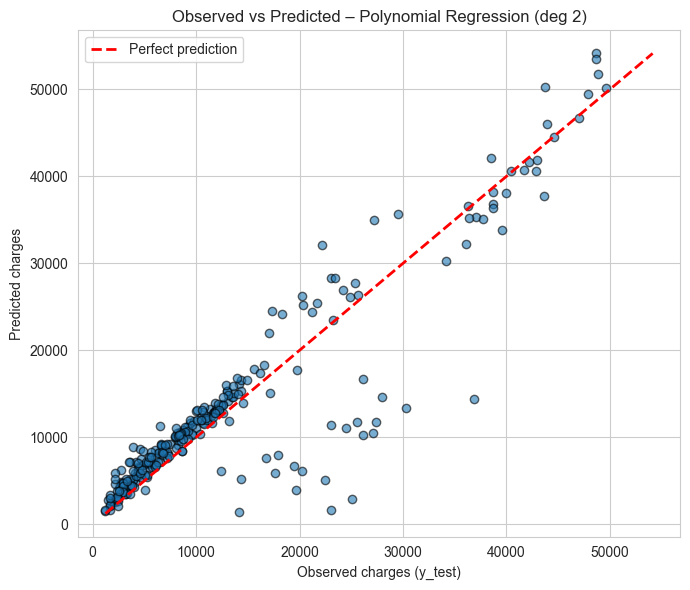

,Actual,Predicted,Difference
0,"5,373.3642","6,912.4487","-1,539.0844"
1,"30,259.9956","13,327.4242","16,932.5714"
2,"8,410.0469","10,638.0283","-2,227.9814"
3,"6,455.8627","8,345.3221","-1,889.4594"
4,"4,133.6416","5,957.9351","-1,824.2935"
5,"10,713.6440","11,672.2198",-958.5758
6,"6,664.6860","8,027.1141","-1,362.4281"
7,"4,347.0234","6,600.6757","-2,253.6523"
8,"3,554.2030","4,361.5364",-807.3334
9,"11,538.4210","11,683.7482",-145.3272


In [36]:
y_pred_best = reg_predictions[best_reg_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best, alpha=0.6, edgecolor='k')
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
plt.plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
plt.xlabel('Observed charges (y_test)')
plt.ylabel('Predicted charges')
plt.title(f'Observed vs Predicted – {best_reg_name}')
plt.legend()
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred_best,
                           'Difference': y_test.values - y_pred_best}).head(10)
comparison

### 2.4 Deriving the Regression Equation — 5 random records
The equation of the best-fit model (printed above) is used to predict `charges` for **5 randomly chosen records**.
The table below can be used to check the hand calculation; the **observed vs predicted scatter plot must be drawn on paper** (as required by the template).

In [37]:
five = data_enc.sample(5, random_state=7)
X_five = five.drop(columns='charges')

intercept, coefs = eq_params[best_reg_name]
if 'Polynomial' in best_reg_name:
    poly = dict(best_reg.steps)['polynomialfeatures']
    X_terms = pd.DataFrame(poly.transform(X_five), columns=coefs.index, index=X_five.index)
else:
    X_terms = X_five[coefs.index]

manual_pred = intercept + X_terms.values @ coefs.values          # equation: intercept + Σ coef × value

five_table = five.copy()
five_table['Predicted (equation)'] = manual_pred.round(2)
five_table['Predicted (model)'] = best_reg.predict(X_five).round(2)
five_table['Error'] = (five_table['charges'] - five_table['Predicted (equation)']).round(2)
five_table

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,Predicted (equation),Predicted (model),Error
918,50,1,32.1100,2,0,"25,333.3328",0,0,0,"12,179.8100","12,179.8100","13,153.5200"
430,60,0,30.5000,0,0,"12,638.1950",0,0,1,"13,793.7000","13,793.7000","-1,155.5100"
51,21,0,33.6300,2,0,"3,579.8287",1,0,0,"7,149.7500","7,149.7500","-3,569.9200"
1210,38,0,30.2100,3,0,"7,537.1639",1,0,0,"10,722.0200","10,722.0200","-3,184.8600"
770,51,1,33.3300,3,0,"10,560.4917",0,1,0,"13,121.7100","13,121.7100","-2,561.2200"


In [38]:
# Non-zero terms of the equation for the 5 records (helps with substitution by hand)
for idx, row in X_terms.iterrows():
    used = row[(row != 0) & (coefs.abs() > 1e-8)]
    parts = ' + '.join(f'({coefs[t]:,.4f} × {t}[{used[t]:g}])' for t in used.index)
    print(f'Record {idx}: charges = {intercept:,.4f} + {parts}')
    print(f'           = {intercept + (used * coefs[used.index]).sum():,.2f}   (observed = {five.loc[idx, "charges"]:,.2f})\n')

Record 918: charges = -1,083.4885 + (-106.5778 × age[50]) + (-795.6535 × sex[1]) + (333.6139 × bmi[32.11]) + (2,023.1641 × children[2]) + (3.8191 × age^2[2500]) + (24.5987 × age*sex[50]) + (0.6628 × age*bmi[1605.5]) + (-9.2840 × age*children[100]) + (-795.6535 × sex^2[1]) + (-13.3987 × sex*bmi[32.11]) + (-260.9565 × sex*children[2]) + (-3.8175 × bmi^2[1031.05]) + (-1.8165 × bmi*children[64.22]) + (-120.9195 × children^2[4])
           = 12,179.81   (observed = 25,333.33)

Record 430: charges = -1,083.4885 + (-106.5778 × age[60]) + (333.6139 × bmi[30.5]) + (36.5774 × region_southwest[1]) + (3.8191 × age^2[3600]) + (0.6628 × age*bmi[1830]) + (56.3164 × age*region_southwest[60]) + (-3.8175 × bmi^2[930.25]) + (-123.4725 × bmi*region_southwest[30.5]) + (36.5774 × region_southwest^2[1])
           = 13,793.70   (observed = 12,638.19)

Record 51: charges = -1,083.4885 + (-106.5778 × age[21]) + (333.6139 × bmi[33.63]) + (2,023.1641 × children[2]) + (-341.2424 × region_northwest[1]) + (3.8191 ×

## 3. Classification Models
### 3.1 Defining the Target Variable as a Category
`charges` is converted into a categorical variable **`charges_category`** using the **median** of charges as the criterion:
- **Low** (0): charges ≤ median
- **High** (1): charges > median

The median gives two **balanced classes**, so accuracy is a fair metric, and it separates policyholders into lower-cost and higher-cost groups for the insurer.

In [39]:
median_charge = data_enc['charges'].median()
data_enc['charges_category'] = np.where(data_enc['charges'] > median_charge, 1, 0)   # 1 = High, 0 = Low
print(f'Median charges (criterion): {median_charge:,.2f}')
print(data_enc['charges_category'].value_counts().rename({0: 'Low (0)', 1: 'High (1)'}))

Xc = data_enc.drop(columns=['charges', 'charges_category'])     # charges is removed to avoid target leakage
yc = data_enc['charges_category']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print('Train:', Xc_train.shape, ' Test:', Xc_test.shape)

Median charges (criterion): 9,369.62
charges_category
High (1)    664
Low (0)     664
Name: count, dtype: int64
Train: (1062, 8)  Test: (266, 8)


### 3.2 Building and Comparing the Classification Models
Models: Logistic Regression, KNN, Naïve Bayes, SVM, Decision Tree, Random Forest (+ Gradient Boosting as an extra model).
KNN, Decision Tree and Random Forest are **optimised with GridSearchCV**. Each model is evaluated on the test set (confusion matrix, errors, accuracy, precision, recall, F1)
and with **5-fold cross-validation** accuracy.

In [40]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'K-Nearest Neighbors': GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                                        {'kneighborsclassifier__n_neighbors': list(range(3, 26, 2))}, cv=skf),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma='scale')),
    'Decision Tree': GridSearchCV(DecisionTreeClassifier(random_state=42),
                                  {'max_depth': [3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5, 10]}, cv=skf),
    'Random Forest': GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=42),
                                  {'max_depth': [4, 6, 8, None], 'min_samples_leaf': [1, 5]}, cv=skf),
    # Extra model (beyond the lecture slides)
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

clf_results = []
for name, model in clf_models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    cm = confusion_matrix(yc_test, pred)
    cv_acc = cross_val_score(model, Xc, yc, cv=skf, scoring='accuracy').mean()
    clf_results.append({'Model': name,
                        'Confusion Matrix': cm,
                        'Errors (FP + FN)': cm[0, 1] + cm[1, 0],
                        'Accuracy': accuracy_score(yc_test, pred),
                        'Precision': precision_score(yc_test, pred),
                        'Recall': recall_score(yc_test, pred),
                        'F1-score': f1_score(yc_test, pred),
                        'CV Accuracy (5-fold)': cv_acc})
    if isinstance(model, GridSearchCV):
        print(f'{name}: best parameters = {model.best_params_}')

clf_df = pd.DataFrame(clf_results)
print('\nClassification Model Results')
clf_df

K-Nearest Neighbors: best parameters = {'kneighborsclassifier__n_neighbors': 7}
Decision Tree: best parameters = {'max_depth': 8, 'min_samples_leaf': 1}
Random Forest: best parameters = {'max_depth': 8, 'min_samples_leaf': 1}

Classification Model Results


,Model,Confusion Matrix,Errors (FP + FN),Accuracy,Precision,Recall,F1-score,CV Accuracy (5-fold)
0,Logistic Regression,"[[121, 12], [13, 120]]",25,0.9060,0.9091,0.9023,0.9057,0.9059
1,K-Nearest Neighbors,"[[125, 8], [18, 115]]",26,0.9023,0.9350,0.8647,0.8984,0.8923
2,Naive Bayes,"[[133, 0], [71, 62]]",71,0.7331,1.0000,0.4662,0.6359,0.7041
3,Support Vector Machine,"[[130, 3], [14, 119]]",17,0.9361,0.9754,0.8947,0.9333,0.9270
4,Decision Tree,"[[124, 9], [16, 117]]",25,0.9060,0.9286,0.8797,0.9035,0.9247
5,Random Forest,"[[128, 5], [17, 116]]",22,0.9173,0.9587,0.8722,0.9134,0.9322
6,Gradient Boosting,"[[127, 6], [15, 118]]",21,0.9211,0.9516,0.8872,0.9183,0.9330


In [41]:
# Printed metrics for each model
for r in clf_results:
    print(f"===== {r['Model']} =====")
    print('Confusion Matrix:\n', r['Confusion Matrix'])
    print(f"Errors (FP + FN): {r['Errors (FP + FN)']}")
    print(f"Accuracy : {r['Accuracy']:.4f}   Precision: {r['Precision']:.4f}   "
          f"Recall: {r['Recall']:.4f}   F1-score: {r['F1-score']:.4f}   CV Accuracy: {r['CV Accuracy (5-fold)']:.4f}\n")

===== Logistic Regression =====
Confusion Matrix:
 [[121  12]
 [ 13 120]]
Errors (FP + FN): 25
Accuracy : 0.9060   Precision: 0.9091   Recall: 0.9023   F1-score: 0.9057   CV Accuracy: 0.9059

===== K-Nearest Neighbors =====
Confusion Matrix:
 [[125   8]
 [ 18 115]]
Errors (FP + FN): 26
Accuracy : 0.9023   Precision: 0.9350   Recall: 0.8647   F1-score: 0.8984   CV Accuracy: 0.8923

===== Naive Bayes =====
Confusion Matrix:
 [[133   0]
 [ 71  62]]
Errors (FP + FN): 71
Accuracy : 0.7331   Precision: 1.0000   Recall: 0.4662   F1-score: 0.6359   CV Accuracy: 0.7041

===== Support Vector Machine =====
Confusion Matrix:
 [[130   3]
 [ 14 119]]
Errors (FP + FN): 17
Accuracy : 0.9361   Precision: 0.9754   Recall: 0.8947   F1-score: 0.9333   CV Accuracy: 0.9270

===== Decision Tree =====
Confusion Matrix:
 [[124   9]
 [ 16 117]]
Errors (FP + FN): 25
Accuracy : 0.9060   Precision: 0.9286   Recall: 0.8797   F1-score: 0.9035   CV Accuracy: 0.9247

===== Random Forest =====
Confusion Matrix:
 [[128 

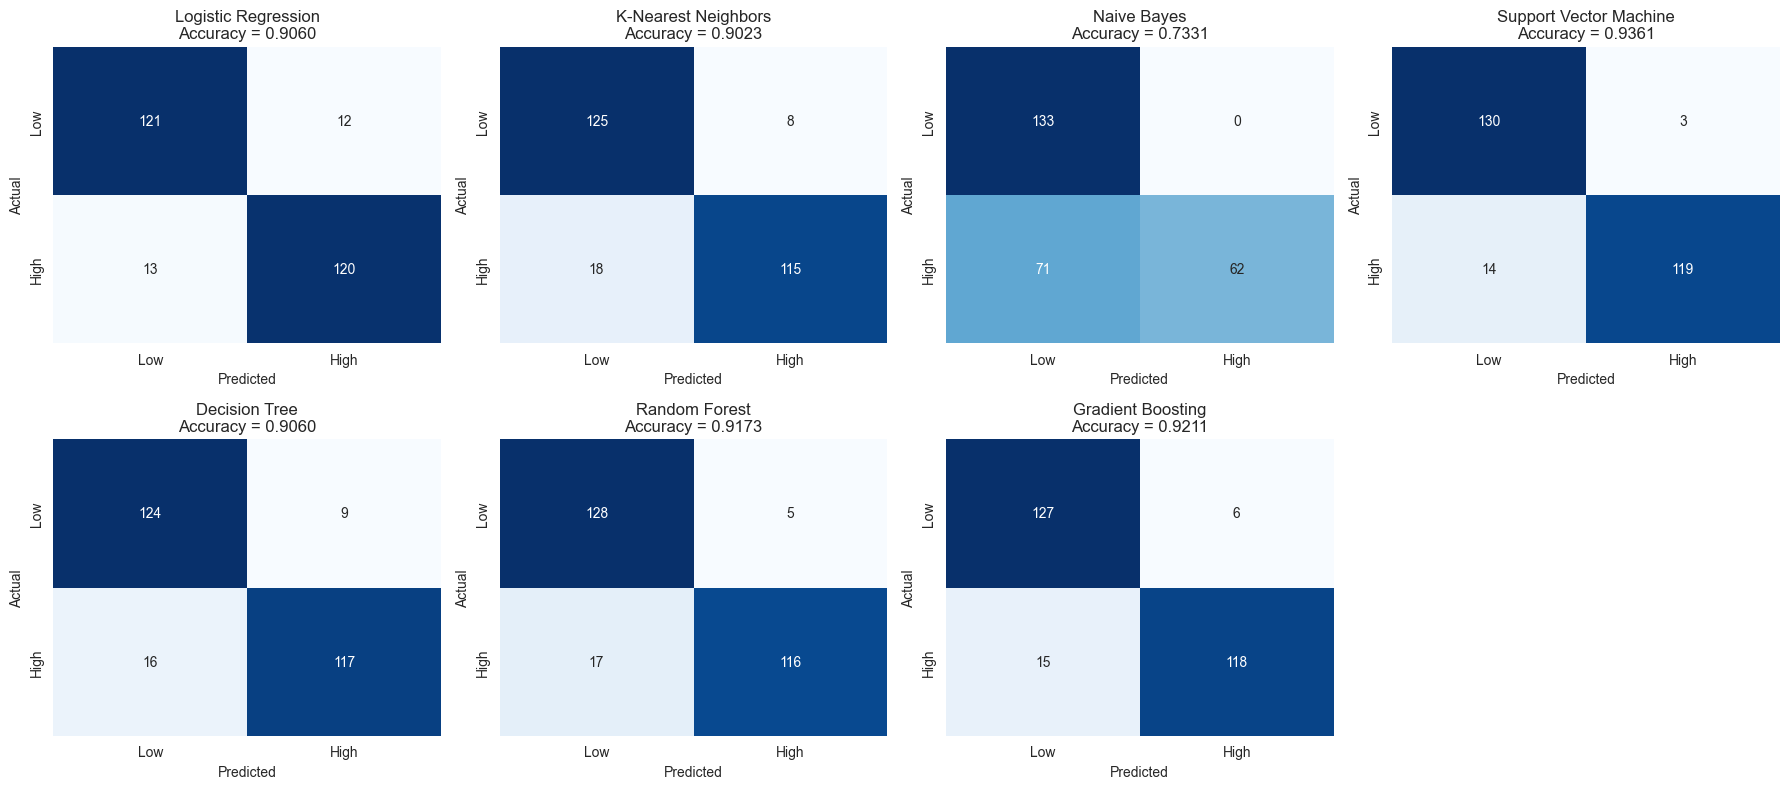

In [42]:
# Confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, r in zip(axes.ravel(), clf_results):
    sns.heatmap(r['Confusion Matrix'], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
    ax.set_title(f"{r['Model']}\nAccuracy = {r['Accuracy']:.4f}")
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

In [43]:
# Best-fit classifier: highest F1-score, ties broken by accuracy then cross-validation accuracy
ranked = clf_df.sort_values(['F1-score', 'Accuracy', 'CV Accuracy (5-fold)'], ascending=False).reset_index(drop=True)
display(ranked.drop(columns='Confusion Matrix').round(4))

best_clf_name = ranked.loc[0, 'Model']
best_clf = clf_models[best_clf_name]
print(f'Best-fit classifier: {best_clf_name}')
print(classification_report(yc_test, best_clf.predict(Xc_test), target_names=['Low', 'High']))

,Model,Errors (FP + FN),Accuracy,Precision,Recall,F1-score,CV Accuracy (5-fold)
0,Support Vector Machine,17,0.9361,0.9754,0.8947,0.9333,0.9270
1,Gradient Boosting,21,0.9211,0.9516,0.8872,0.9183,0.9330
2,Random Forest,22,0.9173,0.9587,0.8722,0.9134,0.9322
3,Logistic Regression,25,0.9060,0.9091,0.9023,0.9057,0.9059
4,Decision Tree,25,0.9060,0.9286,0.8797,0.9035,0.9247
5,K-Nearest Neighbors,26,0.9023,0.9350,0.8647,0.8984,0.8923
6,Naive Bayes,71,0.7331,1.0000,0.4662,0.6359,0.7041


Best-fit classifier: Support Vector Machine
              precision    recall  f1-score   support

         Low       0.90      0.98      0.94       133
        High       0.98      0.89      0.93       133

    accuracy                           0.94       266
   macro avg       0.94      0.94      0.94       266
weighted avg       0.94      0.94      0.94       266



### 3.3 Number of Elements in Each Category (best-fit classifier)
The best classifier predicts the category of **every record in the dataset**, and the number of records in each category is counted.

,Actual count,Predicted count (best classifier)
Low,664,716
High,664,612


Predicted counts on the test set only:
Low     144
High    122
Name: count, dtype: int64


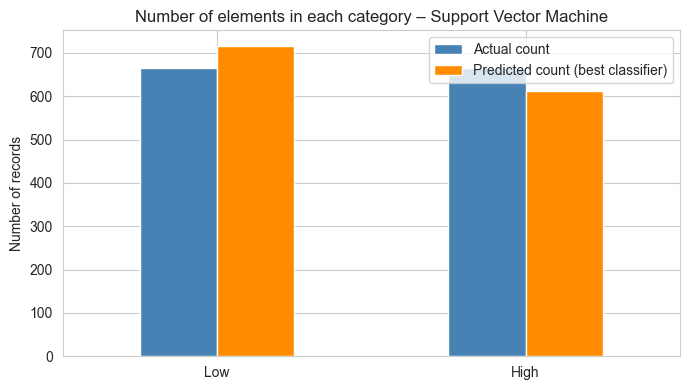

In [44]:
data_enc['predicted_category'] = best_clf.predict(Xc)
counts = pd.DataFrame({
    'Actual count': data_enc['charges_category'].value_counts().sort_index(),
    'Predicted count (best classifier)': data_enc['predicted_category'].value_counts().sort_index(),
}).rename(index={0: 'Low', 1: 'High'})
display(counts)

test_counts = pd.Series(best_clf.predict(Xc_test)).value_counts().sort_index().rename({0: 'Low', 1: 'High'})
print('Predicted counts on the test set only:')
print(test_counts)

counts.plot(kind='bar', figsize=(7, 4), rot=0, color=['steelblue', 'darkorange'])
plt.title(f'Number of elements in each category – {best_clf_name}')
plt.ylabel('Number of records')
plt.tight_layout()
plt.show()

In [45]:
# Example: predict the category for a new policyholder
new_person = pd.DataFrame([{'age': 45, 'sex': 1, 'bmi': 32.0, 'children': 2, 'smoker': 1,
                            'region_northwest': 0, 'region_southeast': 1, 'region_southwest': 0}])
pred_new = best_clf.predict(new_person[Xc.columns])[0]
print('Predicted category for the new policyholder:', 'High' if pred_new == 1 else 'Low')

Predicted category for the new policyholder: High


## 4. Cluster Analysis
Features chosen: **`age`, `bmi`, `charges`** — the three numeric variables that describe a policyholder's risk and cost.
They are standardised before clustering because K-Means and hierarchical clustering are distance-based.

  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1435, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


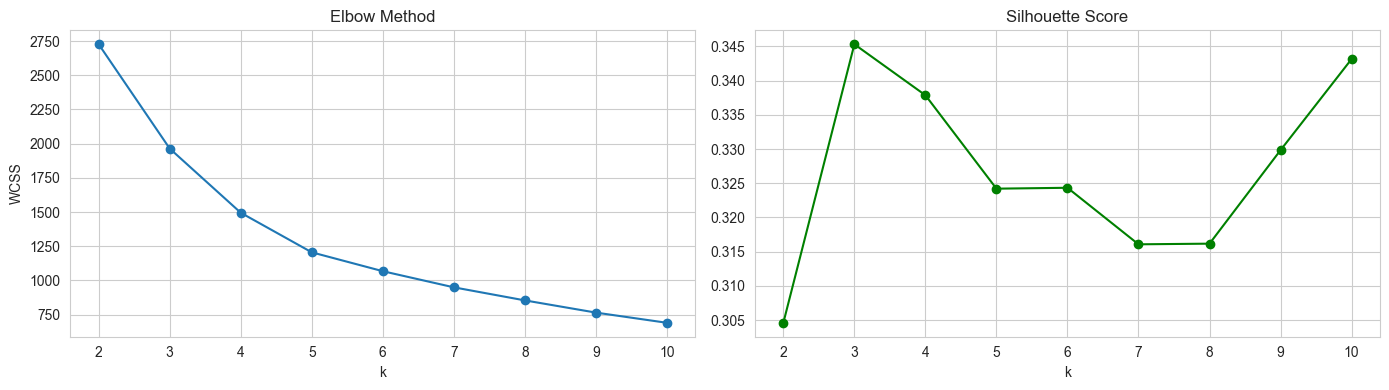

 k       WCSS  Silhouette
 2 2,726.9561      0.3046
 3 1,964.3337      0.3453
 4 1,495.1389      0.3379
 5 1,205.7694      0.3242
 6 1,067.7995      0.3243
 7   949.8601      0.3161
 8   854.3830      0.3162
 9   765.1414      0.3298
10   690.5963      0.3431


In [46]:
cluster_features = ['age', 'bmi', 'charges']
Xk = data[cluster_features]
Xk_scaled = StandardScaler().fit_transform(Xk)

# Optimal number of clusters: Elbow method (WCSS) and Silhouette score
k_range = range(2, 11)
wcss, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xk_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(Xk_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(k_range, wcss, 'o-'); axes[0].set_title('Elbow Method'); axes[0].set_xlabel('k'); axes[0].set_ylabel('WCSS')
axes[1].plot(k_range, sil, 'o-', color='green'); axes[1].set_title('Silhouette Score'); axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'k': list(k_range), 'WCSS': wcss, 'Silhouette': sil}).round(4).to_string(index=False))

In [47]:
# Choice of k: the WCSS curve bends and flattens after k = 4, and the silhouette score at k = 4 (≈0.34)
# is almost the same as the highest value (k = 3, ≈0.35). k = 4 also separates a clear high-cost group,
# so k = 4 is used.
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(Xk_scaled)

# Re-number clusters from lowest to highest average charges (0 = lowest cost) so the numbering is stable
order = pd.Series(data['charges'].values).groupby(labels).mean().sort_values().index
data['KMeans_Cluster'] = pd.Series(labels).map({old: new for new, old in enumerate(order)}).values
print(f'K-Means with k = {optimal_k}, silhouette = {silhouette_score(Xk_scaled, data["KMeans_Cluster"]):.4f}')
data['KMeans_Cluster'].value_counts().sort_index()

K-Means with k = 4, silhouette = 0.3379


KMeans_Cluster
0    488
1    297
2    381
3    162
Name: count, dtype: int64

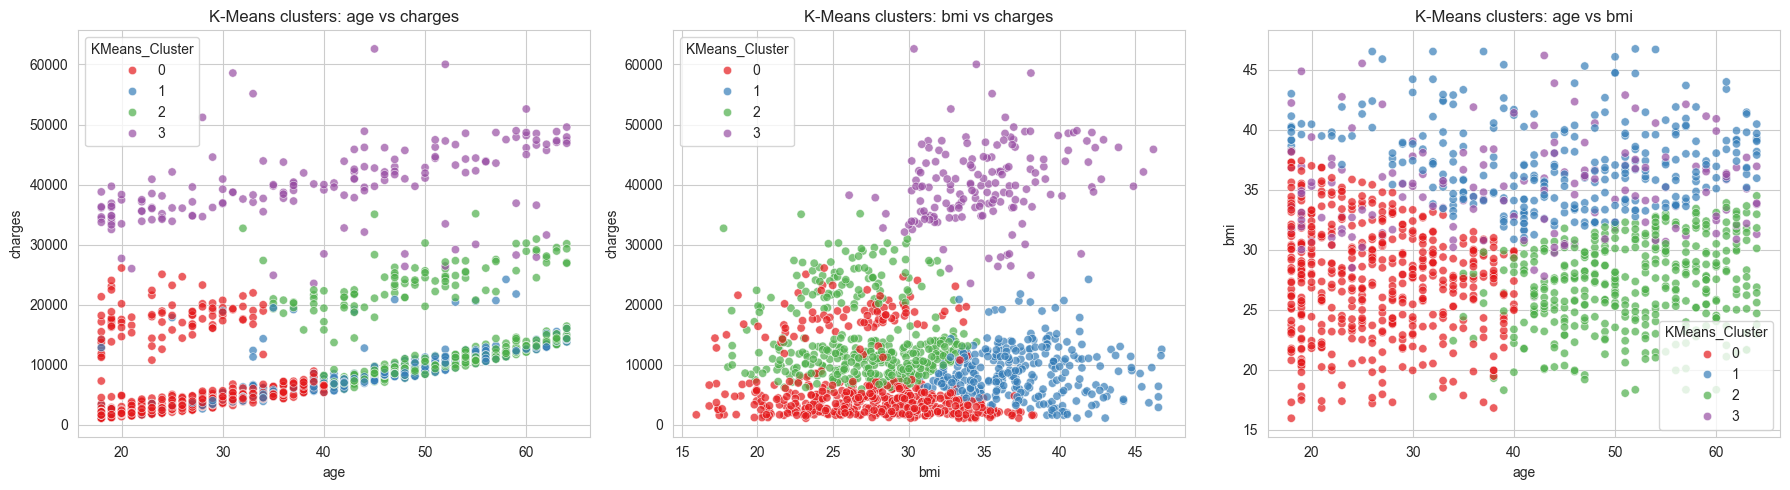

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (xcol, ycol) in zip(axes, [('age', 'charges'), ('bmi', 'charges'), ('age', 'bmi')]):
    sns.scatterplot(data=data, x=xcol, y=ycol, hue='KMeans_Cluster', palette='Set1', alpha=0.7, ax=ax)
    ax.set_title(f'K-Means clusters: {xcol} vs {ycol}')
plt.tight_layout()
plt.show()

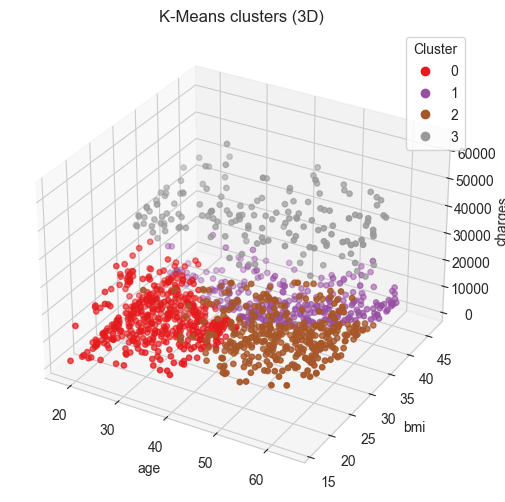

In [49]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(data['age'], data['bmi'], data['charges'], c=data['KMeans_Cluster'], cmap='Set1', s=15)
ax.set_xlabel('age'); ax.set_ylabel('bmi'); ax.set_zlabel('charges')
ax.set_title('K-Means clusters (3D)')
plt.legend(*sc.legend_elements(), title='Cluster')
plt.show()

### 4.1 Hierarchical Clustering

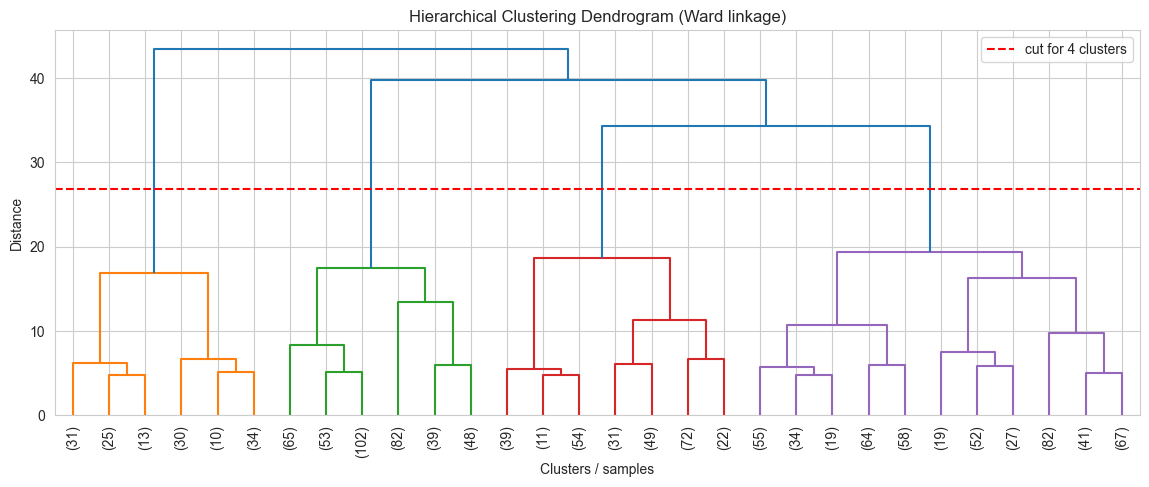

Hierarchical silhouette = 0.2967


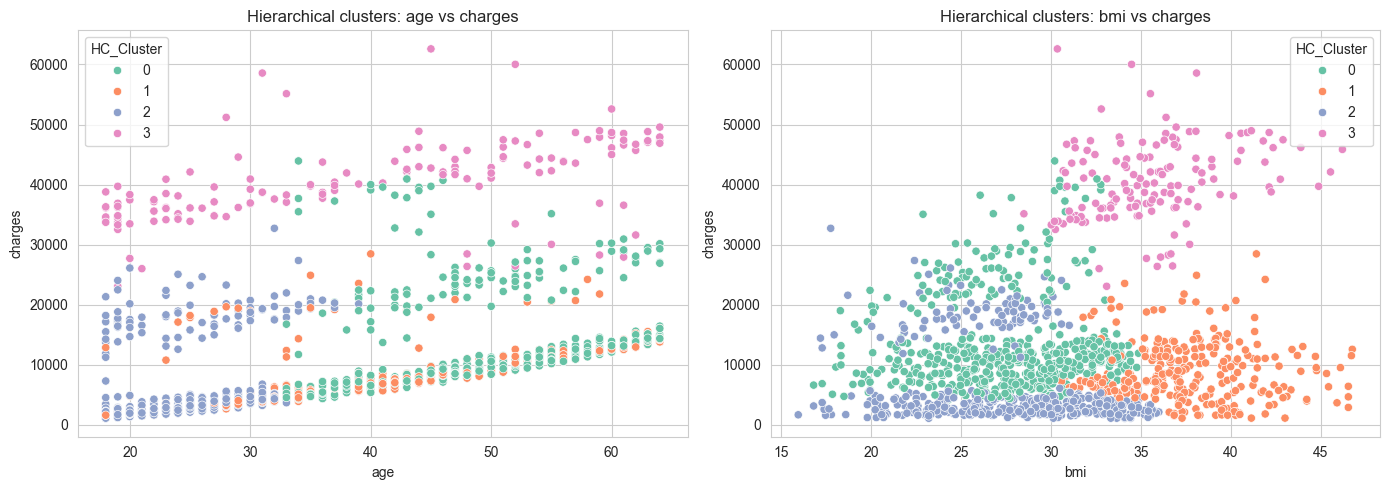

Agreement between K-Means and Hierarchical clusters:


HC_Cluster,0,1,2,3
KMeans_Cluster,,,,
0,90,19,378,1
1,42,253,2,0
2,369,3,9,0
3,17,3,0,142


In [50]:
Z = linkage(Xk_scaled, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.axhline(y=(Z[-optimal_k, 2] + Z[-optimal_k + 1, 2]) / 2, color='r', linestyle='--', label=f'cut for {optimal_k} clusters')
plt.title('Hierarchical Clustering Dendrogram (Ward linkage)')
plt.xlabel('Clusters / samples'); plt.ylabel('Distance')
plt.legend()
plt.show()

hc = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
data['HC_Cluster'] = hc.fit_predict(Xk_scaled)
print(f'Hierarchical silhouette = {silhouette_score(Xk_scaled, data["HC_Cluster"]):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=data, x='age', y='charges', hue='HC_Cluster', palette='Set2', ax=axes[0]).set_title('Hierarchical clusters: age vs charges')
sns.scatterplot(data=data, x='bmi', y='charges', hue='HC_Cluster', palette='Set2', ax=axes[1]).set_title('Hierarchical clusters: bmi vs charges')
plt.tight_layout()
plt.show()

print('Agreement between K-Means and Hierarchical clusters:')
pd.crosstab(data['KMeans_Cluster'], data['HC_Cluster'])

### 4.2 Cluster Profiles

In [51]:
profile = data.groupby('KMeans_Cluster').agg(
    Count=('charges', 'size'),
    Avg_Age=('age', 'mean'),
    Avg_BMI=('bmi', 'mean'),
    Avg_Charges=('charges', 'mean'),
    Smoker_pct=('smoker', lambda s: (s == 'yes').mean() * 100),
    Avg_Children=('children', 'mean'),
).round(2)
profile

,Count,Avg_Age,Avg_BMI,Avg_Charges,Smoker_pct,Avg_Children
KMeans_Cluster,,,,,,
0,488,26.3300,27.6000,"6,243.4600",11.2700,1.0200
1,297,44.2200,37.2700,"8,864.1600",0.0000,1.1700
2,381,51.5100,27.1100,"14,137.8000",18.6400,1.1000
3,162,39.9900,35.1100,"40,071.5200",89.5100,1.1900


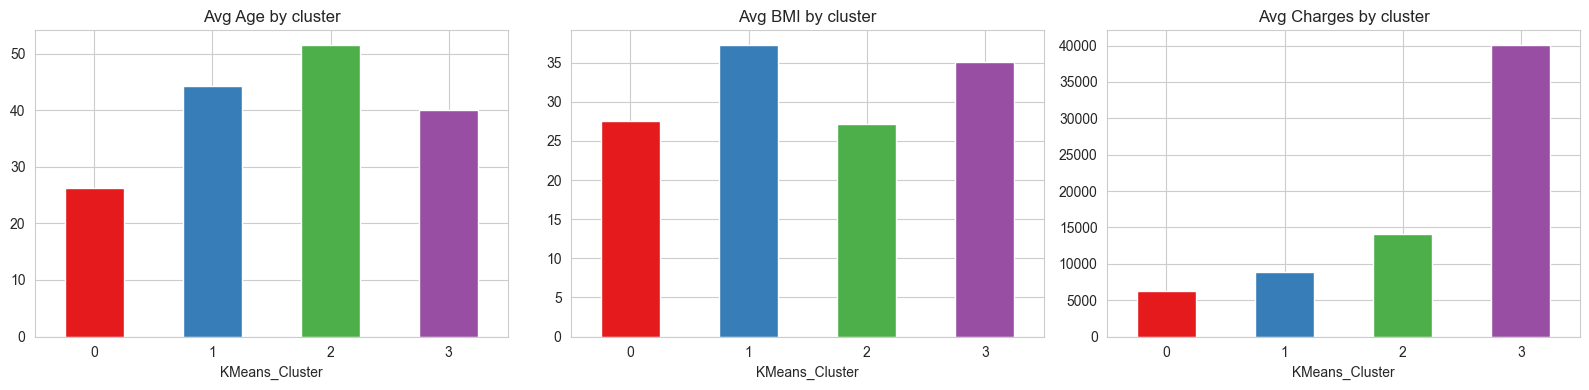

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Avg_Age', 'Avg_BMI', 'Avg_Charges']):
    profile[col].plot(kind='bar', ax=ax, color=sns.color_palette('Set1', optimal_k), rot=0)
    ax.set_title(col.replace('_', ' ') + ' by cluster')
plt.tight_layout()
plt.show()

### 4.3 Strategy for Each Cluster
Clusters are numbered from the lowest (0) to the highest (3) average charges. Average values are from the cluster profile table above.

| Cluster | Profile | Size | Avg age | Avg BMI | Smokers | Avg charges |
|---|---|---|---|---|---|---|
| **0 – Young, low-cost** | Young adults, normal/overweight BMI | 488 | 26 | 27.6 | 11% | ≈ \$6,243 |
| **1 – Obese non-smokers** | Middle-aged, obese (BMI > 30), no smokers | 297 | 44 | 37.3 | 0% | ≈ \$8,864 |
| **2 – Older, moderate-cost** | Older adults (50+), overweight BMI | 381 | 52 | 27.1 | 19% | ≈ \$14,138 |
| **3 – High-risk smokers** | Mostly smokers with high BMI | 162 | 40 | 35.1 | 90% | ≈ \$40,072 |

**Strategies**
- **Cluster 0 – Young, low-cost:** the most profitable and largest group. *Strategy:* attract and retain them with **low-premium, digital/app-based plans**, loyalty discounts and preventive-care benefits (gym membership, annual check-up). Offer **early anti-smoking support** to the 11% who smoke before costs rise.
- **Cluster 1 – Obese non-smokers:** costs are still moderate, but obesity increases the risk of diabetes and heart disease as they age. *Strategy:* **wellness and weight-management programmes** (nutrition advice, fitness tracking) with **premium rewards for reducing BMI**, plus regular screening for diabetes, blood pressure and cholesterol.
- **Cluster 2 – Older, moderate-cost:** charges rise with age. *Strategy:* **age-based pricing** and **chronic-disease management** (regular check-ups, medication plans, telemedicine follow-ups) to prevent expensive hospital admissions; offer senior or family plans to keep these long-term customers.
- **Cluster 3 – High-risk smokers:** the smallest group but by far the most expensive (≈ 5–6× Cluster 0). *Strategy:* apply a **smoker risk surcharge** to price the risk correctly, combined with **mandatory smoking-cessation programmes** that give a premium rebate when the person quits; assign **case managers** for early detection of smoking- and obesity-related disease.

**How this improves the system:** instead of one price for everyone, the insurer can use these segments for **risk-based pricing**, targeted marketing and preventive health programmes, which lowers claims costs and makes premiums fairer.